**MAMOONA IQBAL**

*C2C LAB - Afternoon 1*

Course: AI/ML

**Assignment 53 — Week 6, Day 4**

Topic: Machine Learning

Complete the exercise on decision-tree classification.

Example: Customer Will buy a product or not.


In [203]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report

In [204]:
#Create DataFrame:
data = {
    "CustomerName": [
        "Ali", "Ahmed", "Sara", "Ayesha", "Usman",
        "Fatima", "Bilal", "Zainab", "Hassan", "Maryam",
        "Hamza", "Noor", "Saad", "Hira", "Umar",
        "Iqra", "Daniyal", "Amna", "Talha", "Zoya"
    ],

    "Gender": [
        "Male", "Male", "Female", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female",
        "Male", "Female", "Male", "Female", "Male",
        "Female", "Male", "Female", "Male", "Female"
    ],

    "ProductName": [
        "Laptop", "Mobile", "Headphones", "Tablet", "Laptop",
        "Mobile", "Smartwatch", "Headphones", "Tablet", "Laptop",
        "Mobile", "Smartwatch", "Headphones", "Tablet", "Laptop",
        "Mobile", "Smartwatch", "Headphones", "Tablet", "Laptop"
    ],

    "Age": [
        18, 22, 25, 30, 35, 40, 45, 50, 28, 32,
        24, 38, 42, 55, 20, 48, 27, 36, 44, 31
    ],

    "Income": [
        20000, 25000, 30000, 35000, 40000,
        45000, 50000, 55000, 32000, 38000,
        28000, 42000, 48000, 60000, 22000,
        52000, 31000, 41000, 49000, 36000
    ],

    "Discount": [
        5, 10, 15, 10, 20, 25, 10, 5, 20, 15,
        10, 25, 20, 5, 15, 10, 25, 20, 15, 10
    ],

    "Buy": [
        "No", "No", "Yes", "No", "Yes",
        "Yes", "No", "No", "Yes", "Yes",
        "No", "Yes", "Yes", "No", "No",
        "Yes", "Yes", "Yes", "Yes", "No"
    ]
}


In [205]:
df = pd.DataFrame(data)
df.head(10)

,CustomerName,Gender,ProductName,Age,Income,Discount,Buy
0,Ali,Male,Laptop,18,20000,5,No
1,Ahmed,Male,Mobile,22,25000,10,No
2,Sara,Female,Headphones,25,30000,15,Yes
3,Ayesha,Female,Tablet,30,35000,10,No
4,Usman,Male,Laptop,35,40000,20,Yes
5,Fatima,Female,Mobile,40,45000,25,Yes
6,Bilal,Male,Smartwatch,45,50000,10,No
7,Zainab,Female,Headphones,50,55000,5,No
8,Hassan,Male,Tablet,28,32000,20,Yes
9,Maryam,Female,Laptop,32,38000,15,Yes


In [206]:
print("Shape of Data:",df.shape)

Shape of Data: (20, 7)


In [57]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   CustomerName  20 non-null     object
 1   Gender        20 non-null     object
 2   ProductName   20 non-null     object
 3   Age           20 non-null     int64 
 4   Income        20 non-null     int64 
 5   Discount      20 non-null     int64 
 6   Buy           20 non-null     object
dtypes: int64(3), object(4)
memory usage: 1.2+ KB
None


In [207]:
#X : input features
#y :Target variable: whether the customer buys the product.

X = df[["Gender", "ProductName","Age", "Income", "Discount"]]
y = df["Buy"]

In [208]:
#Encoding:One-Hot_Encoding
X = pd.get_dummies(
    X,
    columns=["Gender", "ProductName"],
    dtype=int
)
X.head()

,Age,Income,Discount,Gender_Female,Gender_Male,ProductName_Headphones,ProductName_Laptop,ProductName_Mobile,ProductName_Smartwatch,ProductName_Tablet
0,18,20000,5,0,1,0,1,0,0,0
1,22,25000,10,0,1,0,0,1,0,0
2,25,30000,15,1,0,1,0,0,0,0
3,30,35000,10,1,0,0,0,0,0,1
4,35,40000,20,0,1,0,1,0,0,0


In [209]:
#Spliting of data into training and testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [210]:
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Training rows: 16
Testing rows: 4


In [211]:
#Decision Tree Model:
model = DecisionTreeClassifier(max_depth=3,random_state=42)

model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [212]:
#Prediction by Model:
y_pred = model.predict(X_test)

print("Actual Results:")
print(list(y_test))

print("\nPredicted Results:")
print(list(y_pred))

Actual Results:
['No', 'Yes', 'Yes', 'No']

Predicted Results:
['No', 'Yes', 'No', 'No']


In [213]:
#Accuracy:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

Model Accuracy: 75.0 %

Classification Report:
              precision    recall  f1-score   support

          No       0.67      1.00      0.80         2
         Yes       1.00      0.50      0.67         2

    accuracy                           0.75         4
   macro avg       0.83      0.75      0.73         4
weighted avg       0.83      0.75      0.73         4



In [214]:
#Predict for new Customer:
#New Customer:
gender="Female"
product="Tablet"
age=55
income=60000
discount=5

new_customer = pd.DataFrame({
    "Gender": [gender],
    "ProductName": [product],
    "Age": [age],
    "Income": [income],
    "Discount": [discount]
})

# Encode the new customer using the same feature structure encoding
new_customer = pd.get_dummies(
    new_customer,
    columns=["Gender", "ProductName"],
    dtype=int
)

# Ensure columns match the training dataset
new_customer = new_customer.reindex(
    columns=X.columns,
    fill_value=0
)

In [215]:
print("New Customer Details:")
new_customer

New Customer Details:


,Age,Income,Discount,Gender_Female,Gender_Male,ProductName_Headphones,ProductName_Laptop,ProductName_Mobile,ProductName_Smartwatch,ProductName_Tablet
0,55,60000,5,1,0,0,0,0,0,1


In [216]:
prediction = model.predict(new_customer)
print("\nNew Customer Details:")
print("Gender:",gender)
print("Product:",product)
print("Age:",age)
print("Income:",income)
print("Discount:",discount)

print("\nWill the customer buy the product?", prediction[0])


New Customer Details:
Gender: Female
Product: Tablet
Age: 55
Income: 60000
Discount: 5

Will the customer buy the product? No


**Assignment 54 — Week 6, Day 4**

**Topic: Machine Learning**

Support Vector Machines (SVM).

In [217]:
# Predict whether a customer will buy a product WITH SVM Model

In [218]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

In [219]:
data = {
    "Age": [
        18, 22, 25, 30, 35, 40, 45, 50, 28, 32,
        24, 38, 42, 55, 20, 48, 27, 36, 44, 31
    ],
    "Income": [
        20000, 25000, 30000, 35000, 40000,
        45000, 50000, 55000, 32000, 38000,
        28000, 42000, 48000, 60000, 22000,
        52000, 31000, 41000, 49000, 36000
    ],
    "Discount": [
        5, 10, 15, 10, 20, 25, 10, 5, 20, 15,
        10, 25, 20, 5, 15, 10, 25, 20, 15, 10
    ],
    "Buy": [
        "No", "No", "Yes", "No", "Yes",
        "Yes", "No", "No", "Yes", "Yes",
        "No", "Yes", "Yes", "No", "No",
        "Yes", "Yes", "Yes", "Yes", "No"
    ]
}


In [220]:
#Create DataFrame
df = pd.DataFrame(data)
df.head(5)

,Age,Income,Discount,Buy
0,18,20000,5,No
1,22,25000,10,No
2,25,30000,15,Yes
3,30,35000,10,No
4,35,40000,20,Yes


In [221]:
# X:input and y: target
X = df[["Age", "Income", "Discount"]]
y = df["Buy"]

In [223]:
#Split the dataset:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [224]:
# Scaling the input features:
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [225]:
# SVM model
model = SVC(kernel="linear")

In [226]:
# train the model:
model.fit(X_train, y_train)

print("SVM Model is Trained.")

SVM Model is Trained.


In [227]:
# Prediction:
y_pred = model.predict(X_test)

print("Actual Results:")
print(list(y_test))

print("\nPredicted Results:")
print(list(y_pred))


Actual Results:
['No', 'Yes', 'Yes', 'No']

Predicted Results:
['Yes', 'Yes', 'Yes', 'Yes']


In [228]:
# Evaluation:
accuracy = accuracy_score(y_test, y_pred)

print("SVM Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred, zero_division=0))

SVM Model Accuracy: 50.0 %

Classification Report:
              precision    recall  f1-score   support

          No       0.00      0.00      0.00         2
         Yes       0.50      1.00      0.67         2

    accuracy                           0.50         4
   macro avg       0.25      0.50      0.33         4
weighted avg       0.25      0.50      0.33         4



In [229]:
# Predict for a new customer
age=44
income=49000
discount=15

new_customer = pd.DataFrame({
    "Age": [age],
    "Income": [income],
    "Discount": [discount]
})

In [230]:
new_customer

,Age,Income,Discount
0,44,49000,15


In [231]:
# Scale the new customer's data
new_customer_scaled = scaler.transform(new_customer)

# Make prediction
prediction = model.predict(new_customer_scaled)

print("New Customer Details:")
print(new_customer)

print("\nWill the customer buy the product?", prediction[0])


New Customer Details:
   Age  Income  Discount
0   44   49000        15

Will the customer buy the product? Yes


**Assignment 55 — Week 6, Day 5**

**Topic: Machine Learning**

Time-series analysis.

In [232]:
import pandas as pd

In [233]:
#Time-Series DataFrame:
dates = pd.date_range("2025-01-01", periods=5, freq="D")

df = pd.DataFrame({
    "Date": dates,
    "Sales": [100, 150, 120, 180, 200]
})

In [234]:
df

,Date,Sales
0,2025-01-01,100
1,2025-01-02,150
2,2025-01-03,120
3,2025-01-04,180
4,2025-01-05,200


In [235]:
#Convert Date into Datetime:

df = pd.DataFrame({
    "Date": ["2025-01-01", "2025-01-02", "2025-01-03"],
    "Sales": [100, 150, 200]
})

df["Date"] = pd.to_datetime(df["Date"])

df

,Date,Sales
0,2025-01-01,100
1,2025-01-02,150
2,2025-01-03,200


In [236]:
print(df.dtypes)

Date     datetime64[ns]
Sales             int64
dtype: object


In [237]:
#Set Date as Index:
df = pd.DataFrame({
    "Date": pd.date_range("2025-01-01", periods=4),
    "Sales": [100, 150, 200, 250]
})

df.set_index("Date", inplace=True)

print(df)

            Sales
Date             
2025-01-01    100
2025-01-02    150
2025-01-03    200
2025-01-04    250


In [238]:
#Resample Daily Sales into Monthly Sales:

dates = pd.date_range("2025-01-01", periods=60, freq="D")

df = pd.DataFrame({
    "Sales": range(1, 61)
}, index=dates)

monthly_sales = df["Sales"].resample("MS").sum()

print(monthly_sales)

2025-01-01     496
2025-02-01    1274
2025-03-01      60
Freq: MS, Name: Sales, dtype: int64


In [239]:
#Calculate a Average:
df = pd.DataFrame({
    "Sales": [100, 120, 140, 160, 180]
})

df["Moving_Average"] = df["Sales"].rolling(3).mean()

print(df)

   Sales  Moving_Average
0    100             NaN
1    120             NaN
2    140           120.0
3    160           140.0
4    180           160.0


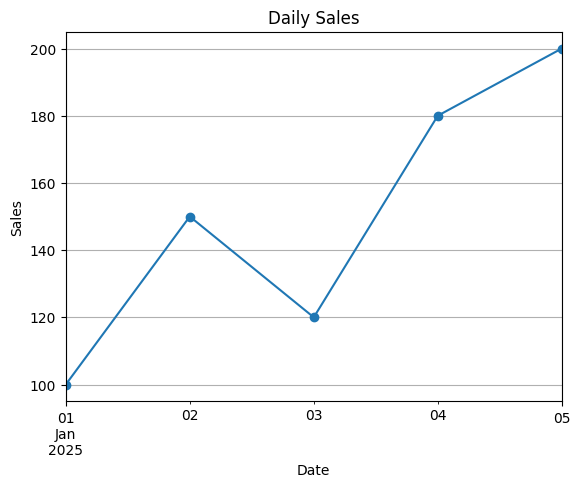

In [240]:
#Plot Time-Series Data:
import matplotlib.pyplot as plt
dates = pd.date_range("2025-01-01", periods=5, freq="D")

df = pd.DataFrame({
    "Sales": [100, 150, 120, 180, 200]
}, index=dates)

df["Sales"].plot(marker="o")

plt.title("Daily Sales")
plt.xlabel("Date")
plt.ylabel("Sales")
plt.grid()
plt.show()